## Camden Goering (cgoering) - MiniProject1 Goals

### Question
How consistent is an author's word usage across their own books, compared to how different two separate authors sound from each other?

### Approach
1. **Same-author comparison:** Mark Twain's *The Adventures of Huckleberry Finn* vs. *The Adventures of Tom Sawyer* -- both set in the same world with overlapping characters, so this isolates Twain's own stylistic fingerprint.
2. **Cross-author comparison:** Mark Twain vs. Jack London's *The Call of the Wild* -- both adventure fiction from a similar era, so differences should reflect authorial style rather than just genre or subject matter.
3. Compute word frequency distributions for each text (excluding stop words), compare the top frequent words across the three texts, and identify words one author favors that the other rarely uses.

### Data Sources
- *The Adventures of Huckleberry Finn* -- Project Gutenberg, https://www.gutenberg.org/ebooks/76.txt.utf-8
- *The Adventures of Tom Sawyer* -- Project Gutenberg, https://www.gutenberg.org/ebooks/74.txt.utf-8
- *The Call of the Wild* -- Project Gutenberg, https://www.gutenberg.org/ebooks/215.txt.utf-8

### Stretch Goal
If time allows, model the frequency of a specific shared word (e.g. "said") as a binomial distribution and compare it across the three texts, per the extra-credit prompt.

# Assignment 1

1. Compare word frequencies between two works of a single author.
1. Compare word frequencies between works of two authors.
1. Are there some words preferred by one author but used less frequently by another author?

Extra credit

1. The frequency of a specific word, e.g., "would" should follow a binomial distribution (each regular word in a document is a trial and with probability p that word is "would". The estimate for p is N("would")/N(regular word)). Do these binomial distributions for your chosen word differ significantly between books of the same author or between authors? 

Project Gutenberg is a good source of for fiction and non-fiction.

E.g below are two most popular books from Project Gutenberg:
- Pride and Prejudice at http://www.gutenberg.org/ebooks/1342.txt.utf-8
- Adventures of Huckleberry Finn at http://www.gutenberg.org/ebooks/76.txt.utf-8

## My Analysis

Same-author: *Huckleberry Finn* vs *Tom Sawyer* (both Twain). Cross-author: Twain vs Jack London's *The Call of the Wild*.

This reuses the same word-frequency idea as the demo above, but adapted for plain-text Gutenberg files instead of an HTML page: strip the Gutenberg header/footer boilerplate, lowercase, split into words, strip punctuation, and drop stop words.

In [1]:
import requests, re, nltk
from collections import Counter

nltk.download('stopwords')
stop_words = set(nltk.corpus.stopwords.words('english') + [
    "'re", "'s", "'d", "'ll", "'m", "'ve", '--', '—', ''
])

def clean_word(w):
    w = re.sub(r'[,"\.\'&\|:@>*;/=_\[\]]', '', w)
    w = re.sub(r'^[0-9]+$', '', w)
    return w

def get_words(url, keep_case=False):
    # grabs the book, cuts off the gutenberg license text, splits into words
    text = requests.get(url).text
    start = text.find('*** START OF')
    end = text.find('*** END OF')
    start = text.find('***', start + 3) + 3 if start != -1 else 0
    end = end if end != -1 else len(text)
    text = text[start:end]
    if not keep_case:
        text = text.lower()
    words = [clean_word(w) for w in text.split()]
    return [w for w in words if w]

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\camgo\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [2]:
def word_freq(words):
    wf = Counter(words)
    for sw in stop_words:
        wf.pop(sw, None)
    return wf

### Getting the books

In [3]:
huck_url = 'https://www.gutenberg.org/ebooks/76.txt.utf-8'   # Huck Finn (Twain)
tom_url  = 'https://www.gutenberg.org/ebooks/74.txt.utf-8'    # Tom Sawyer (Twain)
wild_url = 'https://www.gutenberg.org/ebooks/215.txt.utf-8'   # Call of the Wild (London)

words_huck = get_words(huck_url)
words_tom  = get_words(tom_url)
words_wild = get_words(wild_url)

wf_huck = word_freq(words_huck)
wf_tom  = word_freq(words_tom)
wf_wild = word_freq(words_wild)

print('Huck Finn:', len(words_huck), 'words')
print('Tom Sawyer:', len(words_tom), 'words')
print('Call of the Wild:', len(words_wild), 'words')

Huck Finn: 111075 words
Tom Sawyer: 70785 words
Call of the Wild: 31823 words


In [4]:
def top_n(wf, n=15):
    return sorted(wf.items(), key=lambda x: x[1], reverse=True)[:n]

top_huck = top_n(wf_huck)
top_tom  = top_n(wf_tom)
top_wild = top_n(wf_wild)

for w, c in top_huck:
    print(w, c)

says 637
got 622
said 474
see 468
would 402
come 375
one 366
didn’t 336
get 332
don’t 309
could 303
jim 302
time 296
went 294
warn’t 292


### Same-author comparison: Huck Finn vs Tom Sawyer

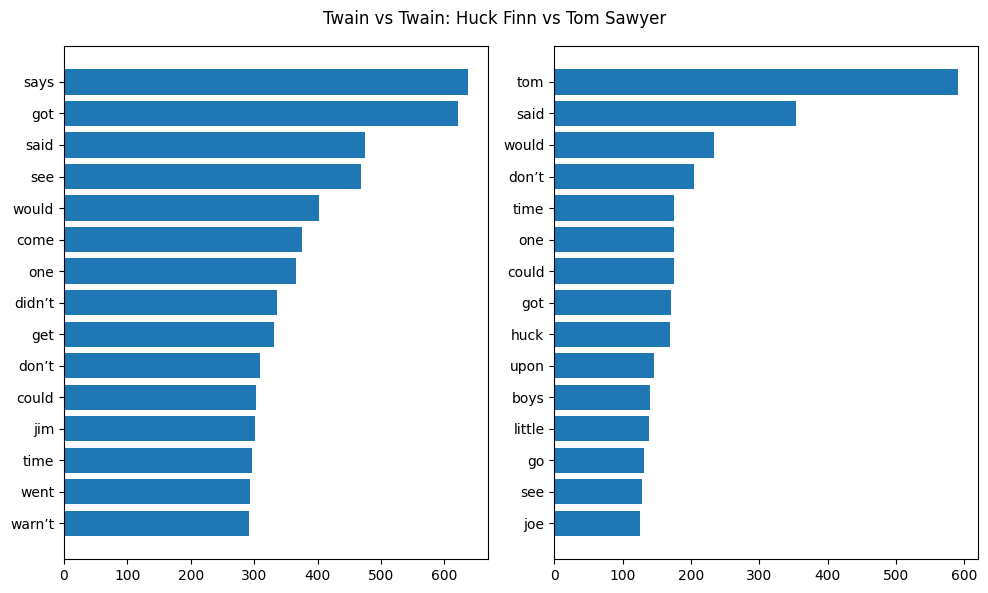

In [5]:
import matplotlib.pyplot as plt
%matplotlib inline

def plot_two_lists(a, b, title):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 6))
    fig.suptitle(title)
    ax1.barh([w for w, c in a], [c for w, c in a])
    ax1.invert_yaxis()
    ax2.barh([w for w, c in b], [c for w, c in b])
    ax2.invert_yaxis()
    plt.tight_layout()
    plt.show()

plot_two_lists(top_huck, top_tom, 'Twain vs Twain: Huck Finn vs Tom Sawyer')

### Cross-author comparison: Twain vs Jack London

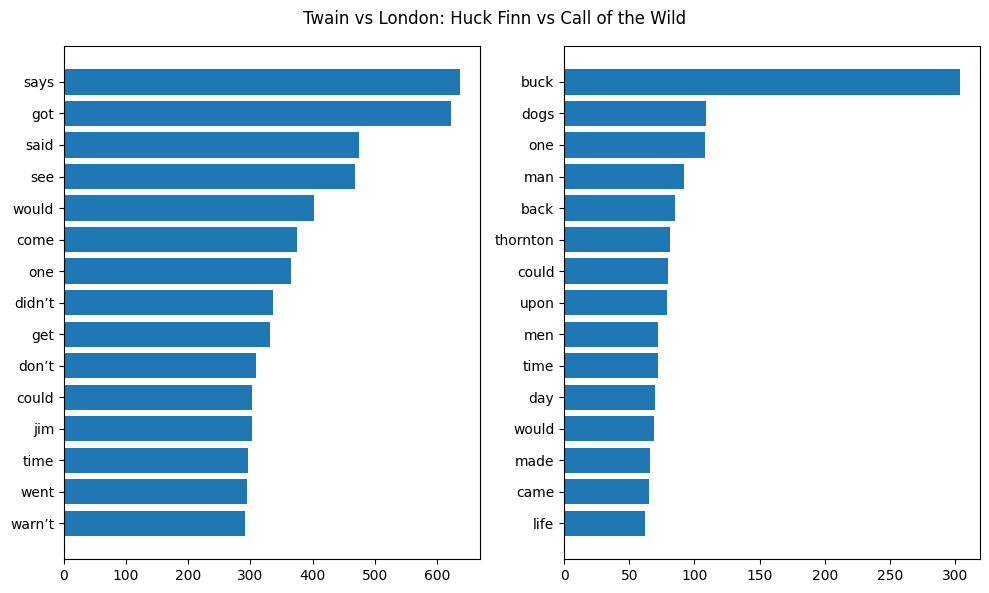

In [6]:
plot_two_lists(top_huck, top_wild, 'Twain vs London: Huck Finn vs Call of the Wild')

### Which words differ the most?

Comparing raw counts isn't fair since the books aren't the same length, so this looks at each word's share of the total text instead.

In [7]:
def relative_freq(wf, total):
    return {w: c / total for w, c in wf.items()}

rel_huck = relative_freq(wf_huck, len(words_huck))
rel_tom  = relative_freq(wf_tom, len(words_tom))
rel_wild = relative_freq(wf_wild, len(words_wild))

def biggest_diff(a, b, n=15):
    words = set(a) | set(b)
    diffs = [(w, a.get(w, 0) - b.get(w, 0)) for w in words]
    diffs.sort(key=lambda x: abs(x[1]), reverse=True)
    return diffs[:n]

print('Huck Finn vs Tom Sawyer (same author)')
for w, d in biggest_diff(rel_huck, rel_tom):
    print(w, round(d, 5))

print()
print('Huck Finn vs Call of the Wild (different author)')
for w, d in biggest_diff(rel_huck, rel_wild):
    print(w, round(d, 5))

Huck Finn vs Tom Sawyer (same author)
tom -0.00651
says 0.00552
got 0.00318
jim 0.00248
see 0.00241
warn’t 0.0024
didn’t 0.00239
de 0.0022
upon -0.00205
en 0.00203
come 0.00184
huck -0.0018
boys -0.00175
joe -0.00175
couldn’t 0.00167

Huck Finn vs Call of the Wild (different author)
buck -0.0093
says 0.0057
got 0.00513
see 0.00387
said 0.00354
dogs -0.00319
didn’t 0.00302
come 0.00284
don’t 0.00269
jim 0.00269
warn’t 0.00263
thornton -0.00255
ain’t 0.00251
upon -0.00247
right 0.0021


### Extra credit: is "said" a binomial thing?

Each word in the book is a trial, success = it's the word we picked. p = count / total words.

In [8]:
word_choice = 'said'

def word_prob(word, words):
    n = len(words)
    k = words.count(word)
    return k / n, k, n

for name, words in [('Huck Finn', words_huck), ('Tom Sawyer', words_tom), ('Call of the Wild', words_wild)]:
    p, k, n = word_prob(word_choice, words)
    print(name, round(p, 5), f'({k}/{n})')

Huck Finn 0.00427 (474/111075)
Tom Sawyer 0.00499 (353/70785)
Call of the Wild 0.00072 (23/31823)


### Filtering out character names

A lot of the biggest differences above are just names (tom, huck, jim, buck, thornton) not actual style. Names are almost always capitalized, regular words usually aren't, so I can grab the text again keeping the capitalization and flag any word that's capitalized more than half the time as probably a name.

In [9]:
def capital_ratio(url):
    words = get_words(url, keep_case=True)
    caps = Counter()
    total = Counter()
    for w in words:
        lw = w.lower()
        total[lw] += 1
        if w[:1].isupper():
            caps[lw] += 1
    return {w: caps[w] / total[w] for w in total}

def likely_names(url, cutoff=0.5):
    ratios = capital_ratio(url)
    return {w for w, r in ratios.items() if r > cutoff}

names_huck = likely_names(huck_url)
names_tom  = likely_names(tom_url)
names_wild = likely_names(wild_url)

print('names found in Huck Finn:', sorted(names_huck)[:15])

names found in Huck Finn: ['a-rab', 'a-rabs', 'ab', 'abner', 'abolitionist', 'abram', 'ab’litionist', 'adam—he', 'admission', 'admitted', 'adolphus', 'adolphus”—meaning', 'african', 'ah', 'alas”']


In [10]:
def biggest_diff_no_names(a, b, exclude, n=15):
    words = (set(a) | set(b)) - exclude
    diffs = [(w, a.get(w, 0) - b.get(w, 0)) for w in words]
    diffs.sort(key=lambda x: abs(x[1]), reverse=True)
    return diffs[:n]

print('Huck Finn vs Tom Sawyer, names taken out')
for w, d in biggest_diff_no_names(rel_huck, rel_tom, names_huck | names_tom):
    print(w, round(d, 5))

print()
print('Huck Finn vs Call of the Wild, names taken out')
for w, d in biggest_diff_no_names(rel_huck, rel_wild, names_huck | names_wild):
    print(w, round(d, 5))

Huck Finn vs Tom Sawyer, names taken out
says 0.00552
got 0.00318
see 0.00241
warn’t 0.0024
didn’t 0.00239
de 0.0022
upon -0.00205
en 0.00203
come 0.00184
boys -0.00175
couldn’t 0.00167
came -0.00159
began -0.0015
get 0.00146
done 0.00137

Huck Finn vs Call of the Wild, names taken out
says 0.0057
got 0.00513
see 0.00387
said 0.00354
dogs -0.00319
didn’t 0.00302
come 0.00284
don’t 0.00269
warn’t 0.00263
ain’t 0.00251
upon -0.00247
right 0.0021
de 0.00208
get 0.00205
en 0.00203


## Presentation Notes


### What is the question?
#### How consistent is an author's word usage and style across their own books? How different does an author sound when compared to another?


### What was the approach?
#### Compare same author (Huck Finn and Tom Sawyer), and compare different author (Call of the Wild).


### What problems did I encounter?
#### A large pool of frequently used word results were just character names ("tom", "jim", etc.) rather than actual styling. 


### What results did I get?
#### Same author comparison showed dialect words consistent with being written in first-person (Huck Finn vs. Tom Sawyer). Cross-author comparison showed shows more dialog wording such as "says", "said", and "got". Binomial estimate showed that Huck Finn (0.00427) and Tom Sawyer (0.00499) were much closer than Call of the Wild (0.00072).


### What new ideas did this generate?
#### Filter out character names and record how the lists change. This filtering actually strengthened the dialect differences of same author vs. different authors. There were some false-positives in my name filtering.

